# Repeat Purchase Prediction
## 01. Data Understanding and Exploratory Data Analysis

### Notebook purpose

This notebook explores the datasets provided for the Repeat Purchase Prediction
project. It documents their structure, assesses data quality and investigates
patterns relevant to future modelling.

The analysis aims to:
- Establish what each dataset and observation represents.
- Understand the variables, identifiers and relationships between datasets.
- Identify missing values, duplicates, inconsistent records and unusual values.
- Explore variable distributions and relationships with the target.
- Compare training and test feature distributions.
- Identify potential data leakage and implications for validation.
- Document findings and recommendations for data preparation.

### Analysis principles

Original datasets will remain unchanged. Any exploratory transformations will
be documented and performed on separate objects.

### Planned structure

1. Environment setup and dataset size assessment
2. Project context and dataset documentation
3. Data loading and structural overview
4. Identifier checks and relationships between datasets
5. Data quality assessment
6. Target distribution
7. Univariate analysis
8. Relationships between features and the target
9. Relationships between features
10. Temporal and customer-level analysis, where supported
11. Training and test distribution comparison
12. Leakage risks and validation considerations
13. Findings and recommendations for data preparation

Data cleaning and feature preparation will be implemented in
“02_preprocessing.ipynb”. Model training and evaluation will be covered in
“03_modelling.ipynb”.

## 1. Environment Setup and Dataset Size Assessment

We begin by importing the required libraries and locating the data folder.
Before loading the datasets, we check their file sizes to assess the resources
needed for exploration.

In [7]:
# Handle file paths without relying on computer-specific locations.
from pathlib import Path

# Locate the project from the current folder or one of its parent folders.
PROJECT_ROOT = next(
    (
        folder
        for folder in [Path.cwd(), *Path.cwd().parents]
        if (folder / "data").is_dir()
        and (folder / "notebooks").is_dir()
    ),
    None,
)

# Give a clear error if the expected project structure cannot be found.
if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Cannot locate the project. Open the notebook within the repository."
    )

DATA_DIR = PROJECT_ROOT / "data"

# Check the expected datasets without loading their contents.
DATA_FILES = [
    "train.csv",
    "test.csv",
    "clientes.csv",
    "sample_submission.csv",
]

total_size_mib = 0

for filename in DATA_FILES:
    file_path = DATA_DIR / filename

    if not file_path.is_file():
        raise FileNotFoundError(f"Missing dataset: {file_path}")

    # Convert file size from bytes to mebibytes (MiB).
    size_mib = file_path.stat().st_size / (1024 ** 2)
    total_size_mib += size_mib

    print(f"{filename}: {size_mib:,.2f} MiB")

print(f"\nTotal size: {total_size_mib:,.2f} MiB")

train.csv: 2.39 MiB
test.csv: 0.36 MiB
clientes.csv: 0.34 MiB
sample_submission.csv: 0.01 MiB

Total size: 3.11 MiB


### 1.1. Imports and Display Settings

Import the libraries used throughout the analysis and configure display
settings to keep tables readable and plots consistent.

In [8]:
# Data manipulation and numerical calculations.
import pandas as pd
import numpy as np

# Charts for exploring distributions and relationships.
import matplotlib.pyplot as plt
import seaborn as sns

# Statistical functions for later analyses.
from scipy import stats

# Display multiple tables explicitly within a notebook cell.
from IPython.display import display

# Show more columns and longer text when inspecting DataFrames.
pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 100)
pd.set_option("display.max_colwidth", 100)

# Format displayed numbers without changing the underlying values.
pd.set_option("display.float_format", "{:,.3f}".format)

# Use consistent styling and colours across plots.
sns.set_theme(style="whitegrid", palette="colorblind")
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["axes.titlesize"] = 14
plt.rcParams["axes.labelsize"] = 11

## 2. Project Context and Dataset Documentation

### 2.1. Prediction Objective

The goal of this project is to predict `repeat_purchase_90d`, a binary target
indicating whether a repeat purchase occurs within 90 days.

We will explore the data, prepare the features and compare classification
models before generating predictions for every observation in `test.csv`.

The `ID` column will be preserved to match predictions to the observations
in the submission.

### 2.2. Available Datasets

| File | Role |
|------|------|
| `train.csv` | Labelled data used for exploration, model development and validation. |
| `test.csv` | Observations for which final predictions will be generated. |
| `clientes.csv` | Optional customer information that can be linked through `customer_id`. |
| `sample_submission.csv` | Template for the prediction submission. |

### 2.3. Organisation of the Work

| Notebook | Scope |
|----------|-------|
| `01_data_understanding.ipynb` | Data exploration, descriptive statistics, quality checks and analysis of distributions and relationships. |
| `02_preprocessing.ipynb` | Data cleaning, customer-data integration, categorical encoding, feature engineering, scaling and feature selection. |
| `03_modelling.ipynb` | Validation strategy, model training, performance evaluation and submission generation. |


## 3. Data Loading and Structural Overview

Load the datasets and inspect their dimensions, column names and first rows
to understand their structure.

In [9]:
# Load the datasets into separate DataFrames.
train = pd.read_csv(DATA_DIR / "train.csv")
test = pd.read_csv(DATA_DIR / "test.csv")
clientes = pd.read_csv(DATA_DIR / "clientes.csv")
sample_submission = pd.read_csv(DATA_DIR / "sample_submission.csv")

# Group the datasets to inspect them consistently.
datasets = {
    "train": train,
    "test": test,
    "clientes": clientes,
    "sample_submission": sample_submission,
}

# Show the dimensions, column names and first five rows of each dataset.
for name, df in datasets.items():
    print(f"\nDataset: {name}")
    print(f"Rows: {df.shape[0]:,} | Columns: {df.shape[1]:,}")
    print(f"Columns: {df.columns.tolist()}")

    display(df.head())


Dataset: train
Rows: 6,534 | Columns: 39
Columns: ['Total a Pagar', 'Total Bruto', 'Total Liquido', 'Total Imp_', 'Total Portes', 'Total Desc_ Global', 'Total Desc_ Linha', 'Custo', 'N_ Detalhes', 'invoice_count_current_purchase', 'repeat_purchase_90d', 'days_since_previous_purchase', 'customer_tenure_days', 'prior_purchase_count', 'prior_total_spend', 'prior_mean_purchase_value', 'prior_std_purchase_value', 'prior_min_purchase_value', 'prior_max_purchase_value', 'prior_mean_gap_days', 'prior_std_gap_days', 'purchase_count_30d', 'spend_30d', 'purchase_count_90d', 'spend_90d', 'purchase_count_180d', 'spend_180d', 'purchase_count_365d', 'spend_365d', 'customer_id', 'payment_type', 'salesperson', 'commercial_zone', 'transport_method', 'warehouse', 'document_series', 'purchase_date', 'ID', 'random_noise']


,Total a Pagar,Total Bruto,Total Liquido,Total Imp_,Total Portes,Total Desc_ Global,Total Desc_ Linha,Custo,N_ Detalhes,invoice_count_current_purchase,repeat_purchase_90d,days_since_previous_purchase,customer_tenure_days,prior_purchase_count,prior_total_spend,prior_mean_purchase_value,prior_std_purchase_value,prior_min_purchase_value,prior_max_purchase_value,prior_mean_gap_days,prior_std_gap_days,purchase_count_30d,spend_30d,purchase_count_90d,spend_90d,purchase_count_180d,spend_180d,purchase_count_365d,spend_365d,customer_id,payment_type,salesperson,commercial_zone,transport_method,warehouse,document_series,purchase_date,ID,random_noise
0,558.110,510.900,453.750,104.360,0.000,0.000,57.150,153.100,4.000,1.000,1,79.000,126.000,2.000,858.300,429.150,112.656,349.490,508.810,47.000,NaN,0.000,0.000,1.000,349.490,2.000,858.300,2.000,858.300,660784,Maybe Tomorrow Payment 10,VLOOKUP Master 9,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 61,Final Excel Warehouse 1,Ctrl Z Series 2,2024-10-29,10000000,-0.660
1,978.800,830.020,795.770,183.030,0.000,0.000,34.250,472.943,32.000,1.000,1,244.000,616.000,5.000,"6,722.830","1,344.566","1,683.795",84.380,"4,222.150",93.000,117.658,0.000,0.000,0.000,0.000,0.000,0.000,4.000,"2,500.680",189146,Maybe Tomorrow Payment 7,VLOOKUP Master 1,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 36,Final Excel Warehouse 1,Ctrl Z Series 1,2017-07-08,10000001,0.925
2,10.330,12.000,8.400,1.930,0.000,0.000,3.600,6.097,1.000,1.000,1,9.000,610.000,90.000,"17,590.080",195.445,190.390,4.540,"1,002.150",6.753,6.384,2.000,111.270,9.000,"1,928.550",28.000,"5,290.250",49.000,"7,899.800",103940,Maybe Tomorrow Payment 9,VLOOKUP Master 1,Decorative Dashboard Zone 4,NaN,Final Excel Warehouse 1,Ctrl Z Series 3,2019-03-19,10000002,-0.259
3,856.830,696.610,696.610,160.220,0.000,0.000,0.000,408.167,9.000,1.000,0,97.000,97.000,1.000,270.330,270.330,NaN,270.330,270.330,NaN,NaN,0.000,0.000,0.000,0.000,1.000,270.330,1.000,270.330,512927,Maybe Tomorrow Payment 7,VLOOKUP Master 4,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 71,Final Excel Warehouse 1,Ctrl Z Series 3,2018-11-10,10000003,1.448
4,"1,616.100","1,488.850","1,313.900",302.200,0.000,0.000,174.950,485.402,33.000,1.000,1,85.000,"1,575.000",25.000,"12,803.020",512.121,406.697,22.580,"1,736.740",62.083,66.247,0.000,0.000,2.000,184.130,4.000,"2,062.500",4.000,"2,062.500",122356,Maybe Tomorrow Payment 12,NaN,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 61,Final Excel Warehouse 1,Ctrl Z Series 2,2021-11-30,10000004,-1.059



Dataset: test
Rows: 986 | Columns: 38
Columns: ['Total a Pagar', 'Total Bruto', 'Total Liquido', 'Total Imp_', 'Total Portes', 'Total Desc_ Global', 'Total Desc_ Linha', 'Custo', 'N_ Detalhes', 'invoice_count_current_purchase', 'days_since_previous_purchase', 'customer_tenure_days', 'prior_purchase_count', 'prior_total_spend', 'prior_mean_purchase_value', 'prior_std_purchase_value', 'prior_min_purchase_value', 'prior_max_purchase_value', 'prior_mean_gap_days', 'prior_std_gap_days', 'purchase_count_30d', 'spend_30d', 'purchase_count_90d', 'spend_90d', 'purchase_count_180d', 'spend_180d', 'purchase_count_365d', 'spend_365d', 'customer_id', 'payment_type', 'salesperson', 'commercial_zone', 'transport_method', 'warehouse', 'document_series', 'purchase_date', 'ID', 'random_noise']


,Total a Pagar,Total Bruto,Total Liquido,Total Imp_,Total Portes,Total Desc_ Global,Total Desc_ Linha,Custo,N_ Detalhes,invoice_count_current_purchase,days_since_previous_purchase,customer_tenure_days,prior_purchase_count,prior_total_spend,prior_mean_purchase_value,prior_std_purchase_value,prior_min_purchase_value,prior_max_purchase_value,prior_mean_gap_days,prior_std_gap_days,purchase_count_30d,spend_30d,purchase_count_90d,spend_90d,purchase_count_180d,spend_180d,purchase_count_365d,spend_365d,customer_id,payment_type,salesperson,commercial_zone,transport_method,warehouse,document_series,purchase_date,ID,random_noise
0,286.370,582.050,232.820,53.550,0.000,0.000,349.230,104.409,22,1,40.000,3905,122,"46,287.230",379.404,528.298,2.720,"3,198.000",31.942,48.035,0,0.000,6,"1,295.820",9,"2,498.900",23,"9,140.120",519184,Maybe Tomorrow Payment 12,VLOOKUP Master 1,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 80,Final Excel Warehouse 1,Ctrl Z Series 2,2026-08-22,10000006,0.622
1,"1,949.250","1,725.000","1,725.000",224.250,0.000,0.000,0.000,0.000,1,1,63.000,3613,58,"243,340.480","4,195.526","2,545.945",569.520,"11,031.740",62.281,46.416,0,0.000,1,"3,137.110",2,"5,086.360",4,"16,252.350",942149,Maybe Tomorrow Payment 7,VLOOKUP Master 1,Decorative Dashboard Zone 4,NaN,Final Excel Warehouse 1,Ctrl Z Series 2,2025-07-26,10000008,-1.319
2,"2,738.710","4,114.830","2,738.710",0.000,0.000,0.000,"1,376.120","1,019.467",99,1,230.000,1786,16,"21,570.230","1,348.139","1,096.651",40.090,"3,363.230",103.733,78.583,0,0.000,0,0.000,0,0.000,4,"4,570.760",386654,Maybe Tomorrow Payment 4,VLOOKUP Master 1,Decorative Dashboard Zone 2,Maybe Tomorrow Delivery 54,Final Excel Warehouse 1,Ctrl Z Series 2,2026-08-22,10000010,1.252
3,726.980,591.040,591.040,135.940,0.000,0.000,0.000,341.649,39,2,234.000,374,3,"3,907.610","1,302.537",881.237,296.370,"1,937.150",70.000,67.882,0,0.000,0,0.000,0,0.000,2,"1,970.460",588088,Maybe Tomorrow Payment 7,VLOOKUP Master 4,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 35,Final Excel Warehouse 1,Ctrl Z Series 2,2025-11-05,10000020,0.988
4,670.760,555.490,545.330,125.430,0.000,0.000,10.160,326.716,13,1,NaN,386,5,"4,877.080",975.416,334.407,546.280,"1,305.090",77.000,43.825,0,0.000,1,759.060,2,"2,062.370",4,"4,330.800",610152,Maybe Tomorrow Payment 7,VLOOKUP Master 4,Decorative Dashboard Zone 1,Maybe Tomorrow Delivery 73,Final Excel Warehouse 1,Ctrl Z Series 2,2026-07-12,10000025,0.512



Dataset: clientes
Rows: 1,143 | Columns: 13
Columns: ['customer_id', 'country_or_region', 'commercial_region', 'island', 'municipality', 'city', 'postal_area', 'postal_code', 'street', 'address', 'customer_type', 'company_name', 'customer_since_year']


,customer_id,country_or_region,commercial_region,island,municipality,city,postal_area,postal_code,street,address,customer_type,company_name,customer_since_year
0,842570,Country CT11: Land of The Final Version,Region RG37: We Will See Later,NaN,NaN,City CY417: Missing Cell Port,NaN,Postal code PC828: #REF! Delivery Route,NaN,Address AD1120: Cell Without a Home,NaN,Excel Is Not A Database Ltd 150,2018
1,770941,Country CT9: Land of The Final Version,NaN,NaN,NaN,NaN,NaN,Postal code PC56: #REF! Delivery Route,NaN,Address AD62: Cell Without a Home,NaN,Excel Is Not A Database Ltd 1064,2021
2,827053,Country CT10: Land of The Final Version,Region RG17: We Will See Later,Island IS2: The Pivot Archipelago,Municipality MU14: Council of Last Minute Edits,NaN,Postal area PA271: Hidden Sheet Sector,Postal code PC827: #REF! Delivery Route,Street ST170: PowerPoint New Walk,Address AD449: Cell Without a Home,NaN,Excel Is Not A Database Ltd 113,2016
3,494648,Country CT10: Land of The Final Version,Region RG17: We Will See Later,Island IS2: The Pivot Archipelago,Municipality MU14: Council of Last Minute Edits,NaN,Postal area PA271: Hidden Sheet Sector,Postal code PC826: #REF! Delivery Route,NaN,Address AD454: Cell Without a Home,NaN,Excel Is Not A Database Ltd 430,2015
4,429291,Country CT10: Land of The Final Version,Region RG17: We Will See Later,Island IS2: The Pivot Archipelago,Municipality MU14: Council of Last Minute Edits,NaN,Postal area PA271: Hidden Sheet Sector,Postal code PC826: #REF! Delivery Route,NaN,Address AD453: Cell Without a Home,NaN,Excel Is Not A Database Ltd 673,2015



Dataset: sample_submission
Rows: 986 | Columns: 2
Columns: ['ID', 'repeat_purchase_90d']


,ID,repeat_purchase_90d
0,10000006,1
1,10000008,1
2,10000010,1
3,10000020,0
4,10000025,1


### 3.1. Initial Observations

| Dataset | Rows | Columns |
|---------|-----:|--------:|
| Training | 6,534 | 39 |
| Test | 986 | 38 |
| Customers | 1,143 | 13 |
| Submission template | 986 | 2 |

The training and test column lists contain the same variables, except for
`repeat_purchase_90d`, which is present only in training.

Each training or test row appears to represent a purchase occasion, combining
current purchase information with customer history. We will check identifiers
and repeated customers to clarify the observation structure.

The variables cover:
- Current purchase amounts, discounts, costs and invoice details.
- Previous purchase frequency, spending and time intervals.
- Purchase counts and spending over 30, 90, 180 and 365 days.
- Customer identifiers, operational categories and purchase dates.

The customer table provides additional geographic and customer information
that may be linked through `customer_id`.

Missing values are visible in both purchase and customer data. Some purchase
counts are displayed as decimals in training and integers in test, which
requires checking the underlying data types and values.

The preview also shows later purchase dates in test than in training.
The complete date ranges will be examined before choosing a validation strategy.

The submission template has the same number of rows as test. Its target
values will be treated as examples of the submission format, not as test labels.

### 3.2. Data Types and Column Overview

Inspect the stored data types, non-missing counts and number of distinct
values in each column. This helps identify categorical variables, possible
identifiers and columns requiring further checks.

In [10]:
# Focus detailed column exploration on training and customer data.
for name, df in {"train": train, "clientes": clientes}.items():
    column_overview = pd.DataFrame({
        "dtype": df.dtypes.astype(str),
        "non_missing": df.notna().sum(),
        "missing": df.isna().sum(),
        "missing_pct": df.isna().mean() * 100,
        "unique_non_missing": df.nunique(dropna=True),
    })

    column_overview.index.name = "variable"

    print(f"\nColumn overview: {name}")
    display(column_overview)


Column overview: train


,dtype,non_missing,missing,missing_pct,unique_non_missing
variable,,,,,
Total a Pagar,float64,6469,65,0.995,6122
Total Bruto,float64,6469,65,0.995,6038
Total Liquido,float64,6469,65,0.995,6093
Total Imp_,float64,6469,65,0.995,5406
Total Portes,float64,6469,65,0.995,215
Total Desc_ Global,float64,6469,65,0.995,109
Total Desc_ Linha,float64,6469,65,0.995,3519
Custo,float64,6469,65,0.995,5736
N_ Detalhes,float64,6469,65,0.995,171



Column overview: clientes


,dtype,non_missing,missing,missing_pct,unique_non_missing
variable,,,,,
customer_id,int64,1143,0,0.000,1143
country_or_region,object,1143,0,0.000,11
commercial_region,object,1029,114,9.974,37
island,object,565,578,50.569,10
municipality,object,984,159,13.911,183
city,object,597,546,47.769,417
postal_area,object,1072,71,6.212,271
postal_code,object,973,170,14.873,828
street,object,545,598,52.318,511


### 3.3. Variable Dictionary

The tables below describe all variables in the purchase and customer datasets.
Descriptions are based on the assignment, column names and observed values.
Exact accounting definitions, monetary units and historical window boundaries
require confirmation from the dataset documentation.

Analytical types describe how variables should be interpreted, independently
of their stored data types.

#### 3.3.1. Current Purchase Information

| Variable | Analytical type | Description |
|----------|-----------------|-------------|
| `Total a Pagar` | Numerical — monetary | Total amount payable for the current purchase. |
| `Total Bruto` | Numerical — monetary | Gross purchase amount, apparently before discounts. |
| `Total Liquido` | Numerical — monetary | Net purchase amount, apparently after discounts and before tax. |
| `Total Imp_` | Numerical — monetary | Tax amount associated with the purchase, inferred from the column name and preview. |
| `Total Portes` | Numerical — monetary | Shipping or delivery charge. |
| `Total Desc_ Global` | Numerical — monetary | Discount applied to the purchase as a whole. |
| `Total Desc_ Linha` | Numerical — monetary | Total discounts applied at line-item level. |
| `Custo` | Numerical — monetary | Recorded cost associated with the purchase; the accounting basis is not specified. |
| `N_ Detalhes` | Numerical — count | Number of purchase detail lines, inferred from the column name. |
| `invoice_count_current_purchase` | Numerical — count | Number of invoices associated with the current purchase occasion. |

#### 3.3.2. Customer Purchase History

| Variable | Analytical type | Description |
|----------|-----------------|-------------|
| `days_since_previous_purchase` | Numerical — duration | Days between the current purchase and the customer's previous purchase. |
| `customer_tenure_days` | Numerical — duration | Customer tenure in days at the purchase date; the starting reference requires confirmation. |
| `prior_purchase_count` | Numerical — count | Number of purchases recorded before the current purchase. |
| `prior_total_spend` | Numerical — monetary | Total spending across previous purchases. |
| `prior_mean_purchase_value` | Numerical — monetary | Mean value of previous purchases. |
| `prior_std_purchase_value` | Numerical — monetary | Standard deviation of previous purchase values. |
| `prior_min_purchase_value` | Numerical — monetary | Minimum value of previous purchases. |
| `prior_max_purchase_value` | Numerical — monetary | Maximum value of previous purchases. |
| `prior_mean_gap_days` | Numerical — duration | Mean interval in days between previous purchases. |
| `prior_std_gap_days` | Numerical — duration | Standard deviation of intervals between previous purchases. |

#### 3.3.3. Purchase Activity in Historical Windows

These variables appear to summarise activity in windows preceding the current
purchase. Whether the current purchase is excluded and how window boundaries
are handled require confirmation.

| Variable | Analytical type | Description |
|----------|-----------------|-------------|
| `purchase_count_30d` | Numerical — count | Number of purchases in the 30-day window. |
| `spend_30d` | Numerical — monetary | Total spending in the 30-day window. |
| `purchase_count_90d` | Numerical — count | Number of purchases in the 90-day window. |
| `spend_90d` | Numerical — monetary | Total spending in the 90-day window. |
| `purchase_count_180d` | Numerical — count | Number of purchases in the 180-day window. |
| `spend_180d` | Numerical — monetary | Total spending in the 180-day window. |
| `purchase_count_365d` | Numerical — count | Number of purchases in the 365-day window. |
| `spend_365d` | Numerical — monetary | Total spending in the 365-day window. |

#### 3.3.4. Identifiers, Operational Categories, Date and Target

| Variable | Analytical type | Description |
|----------|-----------------|-------------|
| `customer_id` | Identifier | Customer identifier shared with the customer table. Multiple purchases can belong to the same customer. |
| `payment_type` | Categorical — nominal | Recorded payment category. |
| `salesperson` | Categorical — nominal | Salesperson category associated with the purchase. |
| `commercial_zone` | Categorical — nominal | Commercial zone associated with the purchase. |
| `transport_method` | Categorical — nominal | Recorded transport or delivery category. |
| `warehouse` | Categorical — nominal | Warehouse associated with the purchase. |
| `document_series` | Categorical — nominal | Series or category of the purchase document. |
| `purchase_date` | Temporal | Date of the purchase, currently stored as text. |
| `ID` | Identifier | Observation identifier used to align predictions with the submission. |
| `random_noise` | Numerical — continuous | Variable whose name suggests artificial random noise; its usefulness will be assessed during feature selection. |
| `repeat_purchase_90d` | Binary target | Indicator of whether a repeat purchase occurs within 90 days. Present only in training. |

The operational category labels appear to be artificial aliases. Their wording
will not be interpreted as a literal description of business operations.

#### 3.3.5. Customer Information

| Variable | Analytical type | Description |
|----------|-----------------|-------------|
| `customer_id` | Identifier | Customer-table key used to link customer information to purchases. |
| `country_or_region` | Categorical — nominal | Recorded country or region category. |
| `commercial_region` | Categorical — nominal | Commercial region assigned to the customer. |
| `island` | Categorical — nominal | Recorded island category, where available. |
| `municipality` | Categorical — nominal | Recorded municipality category. |
| `city` | Categorical — nominal | Recorded city category. |
| `postal_area` | Categorical — nominal | Recorded postal area category. |
| `postal_code` | Categorical — nominal | Postal code category; its label should not be treated as a numerical quantity. |
| `street` | Categorical — nominal | Recorded street category. |
| `address` | Categorical — nominal | Recorded address label, potentially acting as a customer-level identifier. |
| `customer_type` | Categorical — intended | Customer classification field; all values are missing in the supplied table. |
| `company_name` | Categorical — nominal | Company label, potentially acting as a customer-level identifier. |
| `customer_since_year` | Temporal — year | Recorded year when the customer relationship began. |

### 3.4. Findings from the Column Overview

- Training contains 6,534 unique observation IDs and 610 distinct customers.
  Customers therefore have repeated observations, which must be considered
  when choosing a validation strategy.
- The customer table contains 1,143 unique customer IDs, with no missing keys.
  Purchase-to-customer matching still needs to be checked.
- The target has two distinct values and no missing observations.
- Many training variables have exactly 65 missing values. We will check
  whether these belong to the same rows.
- Historical variables have higher missingness, reaching 22.62% for
  `prior_std_gap_days`. Some missing values may reflect insufficient purchase
  history rather than recording errors.
- Count variables are stored as floats in training. Missing values can explain
  this storage type, but we still need to check for fractional or invalid counts.
- `purchase_date` is stored as text and requires date-parsing checks.
- `customer_type` is entirely missing and provides no observed information
  in the supplied customer table.
- `island`, `city` and `street` have substantial missingness. Missing geographic
  values may have different meanings depending on the field.
- Address and company labels have many distinct values. Their potential role
  as identifiers requires review before including them as model features.

### 3.5. Descriptive Statistics — Training Data

Summarise numerical features using counts, central tendency, dispersion and
percentiles. These statistics help identify differences in scale, asymmetry
and values requiring closer inspection.

Identifiers and the target are excluded from the numerical summary because
their averages and standard deviations have no useful interpretation here.
They will be examined separately.

In [11]:
# Separate identifiers and the target from numerical features.
ID_COLUMNS = ["ID", "customer_id"]
TARGET = "repeat_purchase_90d"

numeric_features = [
    column
    for column in train.select_dtypes(include="number").columns
    if column not in ID_COLUMNS + [TARGET]
]

# Include tail percentiles to help inspect unusually small or large values.
numeric_summary = train[numeric_features].describe(
    percentiles=[0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99]
).T

# Add the interquartile range as a measure of dispersion.
numeric_summary["IQR"] = (
    numeric_summary["75%"] - numeric_summary["25%"]
)

# Positive skewness indicates a longer right tail; negative a longer left tail.
numeric_summary["skewness"] = train[numeric_features].skew()

display(numeric_summary)

,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max,IQR,skewness
variable,,,,,,,,,,,,,,
Total a Pagar,"6,469.000",925.556,"1,334.998",0.930,9.378,36.900,188.920,476.740,"1,087.670","3,398.774","6,543.971","22,297.210",898.750,4.209
Total Bruto,"6,469.000",886.153,"1,327.641",0.830,9.234,35.000,175.740,445.740,"1,036.700","3,251.836","6,717.615","21,578.280",860.960,4.313
Total Liquido,"6,469.000",773.336,"1,136.356",0.760,7.624,30.290,154.380,389.910,903.370,"2,838.592","5,675.703","18,127.810",748.990,4.152
Total Imp_,"6,469.000",152.220,225.262,0.000,0.000,2.282,29.930,79.740,184.840,549.120,"1,026.789","4,169.400",154.910,4.836
Total Portes,"6,469.000",1.151,5.844,0.000,0.000,0.000,0.000,0.000,0.000,5.750,11.800,181.060,0.000,19.549
Total Desc_ Global,"6,469.000",0.350,5.117,0.000,0.000,0.000,0.000,0.000,0.000,0.000,7.846,218.490,0.000,27.458
Total Desc_ Linha,"6,469.000",112.466,289.986,0.000,0.000,0.000,0.000,13.130,92.280,540.394,"1,369.040","4,103.440",92.280,5.923
Custo,"6,469.000",328.165,519.507,0.000,0.000,0.000,49.050,152.540,396.061,"1,227.526","2,382.102","7,427.401",347.011,4.611
N_ Detalhes,"6,469.000",21.525,27.713,1.000,1.000,1.000,4.000,11.000,29.000,75.000,128.000,423.000,25.000,2.981


#### Interpretation of Numerical Statistics

**Current purchase values**

Purchase amounts are right-skewed. For example, `Total a Pagar` has a mean
of 925.56 and a median of 476.74, with a maximum of 22,297.21.
Large purchases pull the mean upwards, so the median and interquartile range
provide useful descriptions of typical purchases.

Costs, taxes and line discounts also show positive skewness. Their largest
values require inspection, but size alone does not establish that they are errors.

**Shipping, discounts and invoice counts**

`Total Portes` has a median and third quartile of zero, while
`Total Desc_ Global` remains zero at the 95th percentile. Both variables
are concentrated at zero, with relatively few positive values.

`invoice_count_current_purchase` has a median of one and a maximum of five.
Its zero interquartile range reflects the concentration at one invoice.
An IQR-based outlier rule would flag every value above one, even though
multiple invoices may be valid.

**Purchase history and customer activity**

Customers vary substantially in their recorded purchase history.
`prior_purchase_count` has a median of 11, a mean of 23.46 and a maximum
of 276. Historical spending is also right-skewed: `prior_total_spend`
has a median of 6,754.31 and a mean of 18,908.35.

The median `days_since_previous_purchase` is 57 days, compared with a mean
of 101.53 days. Some customers therefore have much longer gaps between purchases.

The 30-day purchase count and spending variables both have medians of zero,
indicating that at least half of their non-missing observations record
no activity in that window.

**Values requiring consistency checks**

`days_since_previous_purchase` and `prior_mean_gap_days` both reach −4.
Negative elapsed times conflict with their intended interpretation and
require investigation.

`prior_mean_purchase_value` and `spend_365d` both reach 1,000,000,000.
Their means are consequently far above their medians:
- Previous mean purchase value: mean 2,821,825.32 versus median 724.90.
- Annual spending: mean 2,396,534.88 versus median 2,426.61.

These extreme values may be placeholders or corrupted entries. We will
inspect the affected rows and compare them with related history variables.

The minimum recorded `prior_mean_purchase_value` is −2,478.66, while
all non-missing values of `prior_min_purchase_value` are positive.
We need to inspect the affected rows to check whether the historical
mean is consistent with the corresponding minimum and maximum.

**Random noise**

`random_noise` has a mean close to zero, a standard deviation close to one
and little skewness. These summaries resemble those of a standard normal
distribution, but do not establish normality or independence from the target.

### 3.6. Categorical Summary — Training Data

Summarise the operational categories using their number of observed values,
most frequent category and its share of non-missing observations.

Purchase dates are excluded because they will be analysed as temporal data.

In [12]:
# Define operational categories explicitly according to their meaning.
categorical_features = [
    "payment_type",
    "salesperson",
    "commercial_zone",
    "transport_method",
    "warehouse",
    "document_series",
]

# Summarise category counts and the most frequent value in each feature.
categorical_summary = train[categorical_features].describe().T

# Use descriptive labels for the output columns.
categorical_summary = categorical_summary.rename(columns={
    "count": "non_missing",
    "unique": "unique_categories",
    "top": "most_frequent_category",
    "freq": "most_frequent_count",
})

# Calculate the leading category's share among non-missing observations.
categorical_summary["most_frequent_pct"] = (
    categorical_summary["most_frequent_count"]
    / categorical_summary["non_missing"]
    * 100
)

display(categorical_summary)

,non_missing,unique_categories,most_frequent_category,most_frequent_count,most_frequent_pct
variable,,,,,
payment_type,6274,9,Maybe Tomorrow Payment 7,4565,72.761
salesperson,6275,9,VLOOKUP Master 1,4054,64.606
commercial_zone,6469,5,Decorative Dashboard Zone 4,6260,96.769
transport_method,6273,80,Maybe Tomorrow Delivery 72,1119,17.838
warehouse,6274,2,Final Excel Warehouse 1,6253,99.665
document_series,6469,3,Ctrl Z Series 2,2738,42.325


#### Interpretation of Categorical Statistics

The percentages below refer to non-missing observations.

**Category concentration**

`warehouse` is almost constant: its most frequent category accounts for
99.67% of observed values, leaving only 21 observations in the other category.

`commercial_zone` is also highly concentrated, with 96.77% of observed
values belonging to Zone 4. The remaining categories have limited representation.

This imbalance may make comparisons involving rare categories unstable.
It does not, by itself, justify removing either feature.

**Payment and salesperson categories**

`payment_type` and `salesperson` each contain nine observed categories.
Their leading categories account for 72.76% and 64.61% of non-missing
observations, respectively.

Full frequency tables will show how the remaining observations are
distributed and whether some categories are particularly rare.

**Transport and document categories**

`transport_method` has 80 categories, substantially more than the other
operational variables. Its most frequent category represents 17.84%
of observed values. Category frequencies will help assess whether rare
levels need special treatment during preprocessing.

`document_series` contains three categories, with the largest representing
42.33% of observed values. It is less concentrated than warehouse or
commercial zone.

These summaries describe category frequencies. Relationships with repeat
purchase will be examined separately.

## 4. Identifiers and Observation Structure

Check observation IDs and repeated records before examining customer activity.
A customer can have several legitimate purchases, so repeated customer IDs
are not automatically duplicates.

### 4.1. Observation IDs and Duplicate Records

Check whether `ID` is complete and unique. Then compare records with the ID
excluded, since an observation copied under a new ID would otherwise go unnoticed.

A further check excludes `random_noise`, because different noise values could
also hide otherwise identical records. These checks flag records for inspection;
they do not remove observations.

In [13]:
# Count missing IDs and repeated IDs beyond their first occurrence.
id_checks = pd.Series({
    "Total rows": len(train),
    "Missing IDs": train["ID"].isna().sum(),
    "Unique non-missing IDs": train["ID"].nunique(),
    "Repeated non-missing IDs beyond first": (
        train.loc[train["ID"].notna(), "ID"].duplicated().sum()
    ),
})

display(id_checks.to_frame("count"))

# Define comparison columns without modifying the original DataFrame.
columns_without_id = [
    column for column in train.columns
    if column != "ID"
]

columns_without_id_noise = [
    column for column in train.columns
    if column not in ["ID", "random_noise"]
]

# Compare duplicates under different definitions.
duplicate_definitions = {
    "All columns": train.columns.tolist(),
    "Excluding ID": columns_without_id,
    "Excluding ID and random_noise": columns_without_id_noise,
}

duplicate_results = []

for check_name, columns in duplicate_definitions.items():
    duplicate_results.append({
        "check": check_name,
        # Counts additional copies after the first record in each group.
        "duplicates_beyond_first": train.duplicated(
            subset=columns, keep="first"
        ).sum(),
        # Counts every record belonging to a duplicated group.
        "rows_in_duplicate_groups": train.duplicated(
            subset=columns, keep=False
        ).sum(),
    })

duplicate_summary = pd.DataFrame(duplicate_results).set_index("check")

display(duplicate_summary)

# Inspect potential duplicates using the broadest comparison above.
potential_duplicates = train.duplicated(
    subset=columns_without_id_noise,
    keep=False,
)

if potential_duplicates.any():
    print("Potential duplicate records — first 20 rows:")
    display(
        train.loc[potential_duplicates]
        .sort_values(["customer_id", "purchase_date", "ID"])
        .head(20)
    )
else:
    print("No duplicate records found after excluding ID and random_noise.")

,count
Total rows,6534
Missing IDs,0
Unique non-missing IDs,6534
Repeated non-missing IDs beyond first,0


,duplicates_beyond_first,rows_in_duplicate_groups
check,,
All columns,0,0
Excluding ID,10,16
Excluding ID and random_noise,10,16


Potential duplicate records — first 20 rows:


variable,Total a Pagar,Total Bruto,Total Liquido,Total Imp_,Total Portes,Total Desc_ Global,Total Desc_ Linha,Custo,N_ Detalhes,invoice_count_current_purchase,repeat_purchase_90d,days_since_previous_purchase,customer_tenure_days,prior_purchase_count,prior_total_spend,prior_mean_purchase_value,prior_std_purchase_value,prior_min_purchase_value,prior_max_purchase_value,prior_mean_gap_days,prior_std_gap_days,purchase_count_30d,spend_30d,purchase_count_90d,spend_90d,purchase_count_180d,spend_180d,purchase_count_365d,spend_365d,customer_id,payment_type,salesperson,commercial_zone,transport_method,warehouse,document_series,purchase_date,ID,random_noise
3573,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,239651,NaN,NaN,NaN,NaN,NaN,NaN,NaN,10004187,NaN
4378,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,239651,NaN,NaN,NaN,NaN,NaN,NaN,NaN,10005141,NaN
2036,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,258332,NaN,NaN,NaN,NaN,NaN,NaN,NaN,10002381,NaN
4493,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,258332,NaN,NaN,NaN,NaN,NaN,NaN,NaN,10005269,NaN
5632,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,258332,NaN,NaN,NaN,NaN,NaN,NaN,NaN,10006618,NaN
5860,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,264090,NaN,NaN,NaN,NaN,NaN,NaN,NaN,10006879,NaN
6456,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,264090,NaN,NaN,NaN,NaN,NaN,NaN,NaN,10007583,NaN
839,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,334782,NaN,NaN,NaN,NaN,NaN,NaN,NaN,10000983,NaN
3178,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,334782,NaN,NaN,NaN,NaN,NaN,NaN,NaN,10003718,NaN
393,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,755628,NaN,NaN,NaN,NaN,NaN,NaN,NaN,10000457,NaN


#### Interpretation of Identifier and Duplicate Checks

All 6,534 observation IDs are present and unique.

Including every column produces no exact duplicates. Excluding `ID`
identifies 10 additional matching records across 16 rows, forming six groups.
Excluding `random_noise` produces the same result.

Inspection shows that all 16 flagged rows contain only an observation ID,
customer ID and target value. Their purchase dates, amounts, history and
operational categories are missing.

Pandas treats matching missing values as equal when detecting duplicates.
Consequently, these rows match on customer and target, but there is insufficient
information to establish whether they represent the same purchase.

No rows are removed at this stage. These records will be investigated further
as part of the missing-data analysis.

### 4.2. Repeated Customers and Purchase Granularity

Measure how observations are distributed across customers and check whether
the same customer appears more than once on the same recorded purchase date.

Repeated customers are expected in purchase data. Repeated customer-date pairs
require inspection because they may represent separate purchases, duplicated
records or a different aggregation level.

In [14]:
# Count observations per customer, including records with missing purchase data.
customer_record_counts = train.groupby("customer_id").size()

# Identify customers represented by more than one observation.
repeated_customers = customer_record_counts > 1

customer_summary = pd.Series({
    "Unique customers": len(customer_record_counts),
    "Customers with one observation": (customer_record_counts == 1).sum(),
    "Customers with multiple observations": repeated_customers.sum(),
    "Rows belonging to repeated customers": (
        customer_record_counts.loc[repeated_customers].sum()
    ),
    "Median observations per customer": customer_record_counts.median(),
    "Maximum observations per customer": customer_record_counts.max(),
})

display(customer_summary.to_frame("value"))

# Describe the full distribution to assess customer representation.
display(
    customer_record_counts.describe(
        percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
    ).to_frame("observations_per_customer")
)

# Exclude missing keys: unknown dates cannot establish a shared purchase date.
known_purchase_keys = train.dropna(
    subset=["customer_id", "purchase_date"]
)

# Count records for each customer and recorded date.
customer_date_counts = (
    known_purchase_keys
    .groupby(["customer_id", "purchase_date"])
    .size()
    .rename("record_count")
)

repeated_customer_dates = customer_date_counts[
    customer_date_counts > 1
]

print(
    "\nRows excluded from customer-date check due to missing keys:",
    len(train) - len(known_purchase_keys),
)
print("Repeated customer-date pairs:", len(repeated_customer_dates))
print(
    "Rows in repeated customer-date pairs:",
    int(repeated_customer_dates.sum()),
)

# Show the most repeated pairs for subsequent inspection.
display(
    repeated_customer_dates
    .sort_values(ascending=False)
    .head(20)
    .to_frame()
)

,value
Unique customers,610.000
Customers with one observation,157.000
Customers with multiple observations,453.000
Rows belonging to repeated customers,"6,377.000"
Median observations per customer,4.000
Maximum observations per customer,277.000


,observations_per_customer
count,610.000
mean,10.711
std,19.969
min,1.000
25%,1.000
50%,4.000
75%,12.000
90%,28.000
95%,42.550
99%,79.460



Rows excluded from customer-date check due to missing keys: 65
Repeated customer-date pairs: 0
Rows in repeated customer-date pairs: 0


,,record_count
customer_id,purchase_date,


#### Interpretation of Customer Repetition and Purchase Granularity

Training contains 610 customers, of whom 453 have multiple observations
and 157 appear once. Repeated customers account for 6,377 rows, or 97.60%
of the training data.

Customer representation is uneven. The median is four observations per
customer, compared with a mean of 10.71, and the most represented customer
has 277 observations. These counts describe representation in the supplied
training sample, not necessarily each customer's complete purchase history.

Among the 6,469 rows with non-missing customer and date keys, no
customer-date pair is repeated. This supports interpreting an observation
as a purchase occasion at customer-date level, potentially covering
multiple invoices.

The remaining 65 rows have missing purchase dates, so their customer-date
uniqueness cannot be assessed.

Repeated customer IDs are expected and are not grounds for removing rows.
For validation, a random row split could place the same customers in both
training and validation. A chronological split assesses future purchases,
whereas a customer-grouped split assesses generalisation to unseen customers.
The final choice will depend on the prediction setting and test structure.

### 4.3. Matching Inputs and Different Target Values

Check whether records with identical observed inputs have different target
values. Observation IDs and random noise are excluded from the comparison,
while customer IDs remain included.

Matching incomplete records do not necessarily describe the same purchase.
The results must therefore be interpreted alongside the availability of
purchase information.

In [15]:
# Compare input records without the target, observation ID or random noise.
comparison_features = [
    column for column in train.columns
    if column not in ["ID", "random_noise", TARGET]
]

# Keep missing values in the grouping so incomplete records are also examined.
input_groups = (
    train.groupby(comparison_features, dropna=False)
    .agg(
        record_count=("ID", "size"),
        target_values=(TARGET, "nunique"),
    )
    .reset_index()
)

# Find matching input groups containing both target classes.
conflicting_groups = input_groups.loc[
    (input_groups["record_count"] > 1)
    & (input_groups["target_values"] > 1)
]

print("Matching input groups with different targets:", len(conflicting_groups))
print(
    "Rows in these groups:",
    int(conflicting_groups["record_count"].sum()),
)

# Recover the corresponding records for inspection.
if not conflicting_groups.empty:
    conflicting_records = train.merge(
        conflicting_groups[comparison_features],
        on=comparison_features,
        how="inner",
        validate="many_to_one",
    )

    # Count available purchase fields, excluding identifiers and the target.
    purchase_fields = [
        column for column in comparison_features
        if column != "customer_id"
    ]

    conflicting_records["observed_purchase_fields"] = (
        conflicting_records[purchase_fields].notna().sum(axis=1)
    )

    display(
        conflicting_records[
            [
                "ID", "customer_id", "purchase_date", TARGET,
                "observed_purchase_fields",
            ]
        ]
        .sort_values(["customer_id", "ID"])
    )
else:
    print("No matching input groups contain different target values.")

Matching input groups with different targets: 2
Rows in these groups: 4


,ID,customer_id,purchase_date,repeat_purchase_90d,observed_purchase_fields
0,10000678,427118,NaN,1,0
1,10000870,427118,NaN,0,0
2,10006373,475032,NaN,1,0
3,10007096,475032,NaN,0,0


#### Interpretation of Matching Inputs and Different Targets

Two matching-input groups contain different target values, involving four
rows and two customers: `427118` and `475032`.

All four rows have zero observed purchase fields. Only their observation
IDs, customer IDs and target values are available.

These results do not establish contradictory labels for the same purchase.
The records may represent different purchase occasions whose details are
missing. No labels are changed and no records are removed at this stage.

## 5. Data Quality Assessment

Investigate missing information, invalid values and inconsistencies.
Checks are performed on the original training data; cleaning decisions
will be implemented in the preprocessing notebook.

### 5.1. Missing Values by Column and Row

Measure missingness across columns, rows and individual cells. Identify
records with no purchase information and check whether the variables
with exactly 65 missing values share the same affected rows.

In [16]:
# Exclude identifiers and the target when measuring purchase-data availability.
purchase_columns = [
    column for column in train.columns
    if column not in ["ID", "customer_id", TARGET, "random_noise"]
]

# Measure missingness across purchase fields.
purchase_missing = train[purchase_columns].isna()
missing_per_row = purchase_missing.sum(axis=1)
no_purchase_information = purchase_missing.all(axis=1)

# Summarise rows, columns and cells separately.
missing_overview = pd.Series({
    "Purchase fields assessed": len(purchase_columns),
    "Rows with any missing purchase field": purchase_missing.any(axis=1).sum(),
    "Rows with any missing purchase field (%)": (
        purchase_missing.any(axis=1).mean() * 100
    ),
    "Rows with all purchase fields missing": no_purchase_information.sum(),
    "Rows with all purchase fields missing (%)": (
        no_purchase_information.mean() * 100
    ),
    "Purchase columns containing missing values": (
        purchase_missing.any(axis=0).sum()
    ),
    "Missing purchase cells": purchase_missing.sum().sum(),
    "Missing purchase cells (%)": (
        purchase_missing.to_numpy().mean() * 100
    ),
})

display(missing_overview.to_frame("value"))

# Show missingness for every training column, retaining complete columns.
missing_by_column = pd.DataFrame({
    "missing_count": train.isna().sum(),
    "missing_pct": train.isna().mean() * 100,
}).sort_values("missing_count", ascending=False)

display(missing_by_column)

# Show how many rows have each number of missing purchase fields.
row_missing_distribution = (
    missing_per_row.value_counts()
    .sort_index()
    .rename_axis("missing_purchase_fields")
    .to_frame("rows")
)

row_missing_distribution["row_pct"] = (
    row_missing_distribution["rows"] / len(train) * 100
)

display(row_missing_distribution)

# Check whether all columns with 65 missing values share the same null mask.
columns_missing_65 = train.columns[train.isna().sum().eq(65)].tolist()

if columns_missing_65:
    reference_mask = train[columns_missing_65[0]].isna()

    same_missing_rows = all(
        train[column].isna().equals(reference_mask)
        for column in columns_missing_65
    )

    print("\nColumns with exactly 65 missing values:", columns_missing_65)
    print("All share the same missing rows:", same_missing_rows)

    # Test whether that shared pattern is exactly the fully missing purchase rows.
    if same_missing_rows:
        print(
            "Same rows as those with all purchase fields missing:",
            reference_mask.equals(no_purchase_information),
        )

,value
Purchase fields assessed,35.000
Rows with any missing purchase field,"2,605.000"
Rows with any missing purchase field (%),39.868
Rows with all purchase fields missing,65.000
Rows with all purchase fields missing (%),0.995
Purchase columns containing missing values,35.000
Missing purchase cells,"9,753.000"
Missing purchase cells (%),4.265


,missing_count,missing_pct
variable,,
prior_std_gap_days,1478,22.620
prior_mean_gap_days,1308,20.018
prior_std_purchase_value,1113,17.034
prior_mean_purchase_value,862,13.193
days_since_previous_purchase,861,13.177
prior_max_purchase_value,668,10.223
prior_min_purchase_value,668,10.223
transport_method,261,3.994
warehouse,260,3.979


,rows,row_pct
missing_purchase_fields,,
0,3929,60.132
1,1287,19.697
2,190,2.908
3,354,5.418
4,100,1.530
5,6,0.092
7,511,7.821
8,86,1.316
9,6,0.092



Columns with exactly 65 missing values: ['Total a Pagar', 'Total Bruto', 'Total Liquido', 'Total Imp_', 'Total Portes', 'Total Desc_ Global', 'Total Desc_ Linha', 'Custo', 'N_ Detalhes', 'invoice_count_current_purchase', 'customer_tenure_days', 'prior_purchase_count', 'prior_total_spend', 'purchase_count_30d', 'spend_30d', 'purchase_count_90d', 'spend_90d', 'purchase_count_180d', 'spend_180d', 'purchase_count_365d', 'commercial_zone', 'document_series', 'purchase_date', 'random_noise']
All share the same missing rows: True
Same rows as those with all purchase fields missing: True


#### Interpretation of Missing Values

Of the 6,534 training observations, 2,605 (39.87%) have at least one missing
purchase field, while 3,929 (60.13%) are complete across the 35 assessed fields.
Missing cells represent 4.27% of these fields overall.

Missingness therefore affects a substantial number of observations, even
though its share across individual cells is relatively small. Dropping every
incomplete row would remove almost 40% of training data.

**Rows without purchase information**

There are 65 observations (0.99%) with all 35 purchase fields missing.
Their `random_noise` values are also missing; only `ID`, `customer_id`
and the target remain available.

Every column with exactly 65 missing values shares this same set of rows.
This confirms a common missingness pattern across these records, although
the cause is unknown.

This pattern also explains the incomplete records flagged by the earlier
duplicate checks. Their treatment will be considered separately from
partially missing observations.

**Partially missing observations**

The most common incomplete pattern is one missing purchase field,
affecting 1,287 observations (19.70%). Another 511 observations (7.82%)
have seven missing fields. Counts alone do not establish whether these
rows share the same missing columns.

Historical summaries have the highest missingness:
- `prior_std_gap_days`: 22.62%.
- `prior_mean_gap_days`: 20.02%.
- `prior_std_purchase_value`: 17.03%.

Some historical statistics may be undefined when a customer has insufficient
previous purchases. We will compare their missingness with
`prior_purchase_count` before treating all missing values as recording errors.

No imputation or row removal is applied during this assessment.

## 6. Target Analysis

The target variable `repeat_purchase_90d` indicates whether the same customer
makes another purchase within the following 90 days.

This section examines the distribution of the target and assesses whether the
classes are balanced.

In [17]:
# Count observations in each target class.
target_counts = train["repeat_purchase_90d"].value_counts().sort_index()

# Calculate the percentage of observations in each class.
target_percentages = (
    train["repeat_purchase_90d"].value_counts(normalize=True).sort_index() * 100
)

# Combine counts and percentages into one summary table.
target_summary = pd.DataFrame({
    "count": target_counts,
    "percentage": target_percentages
})

display(target_summary)

,count,percentage
repeat_purchase_90d,,
0,2880,44.077
1,3654,55.923


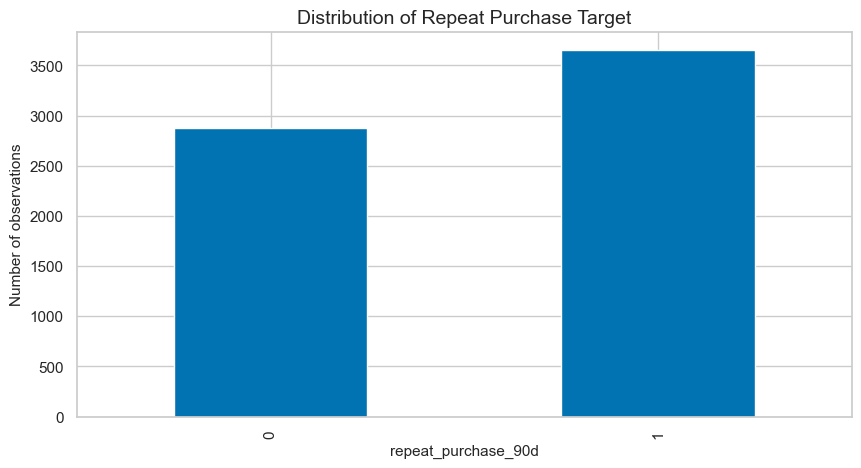

In [18]:
# Plot the number of observations in each target class.
target_counts.plot(
    kind="bar",
    title="Distribution of Repeat Purchase Target",
    xlabel="repeat_purchase_90d",
    ylabel="Number of observations"
);

### Interpretation of Target Distribution

The target variable "repeat_purchase_90d" contains two classes.
A value of 0 indicates that the customer does not make another purchase within the
following 90 days, while a value of 1 indicates that the customer does.

In the training data:
- 2,880 observations (44.08%) belong to class 0
- 3,654 observations (55.92%) belong to class 1

The target is therefore relatively balanced, although class 1 is slightly more
frequent than class 0. The difference between the two classes is not large
enough to indicate a severe class imbalance. This distribution should, however, be considered when evaluating the classification models.

### 6.2 Target and Previous Purchase Behaviour

To investigate whether repeat-purchase behaviour differs according to
customers' previous activity, we examine the relationship between
`prior_purchase_count` and the target variable.

`prior_purchase_count` represents the number of purchases recorded before the
current purchase.


In [19]:
# Compare previous purchase frequency across the two target classes.
prior_purchase_summary = (
    train.groupby("repeat_purchase_90d")["prior_purchase_count"]
    .agg(["count", "mean", "median", "min", "max"])
)

display(prior_purchase_summary)

,count,mean,median,min,max
repeat_purchase_90d,,,,,
0,2848,10.539,6.000,0.000,276.000
1,3621,33.619,17.000,0.000,275.000


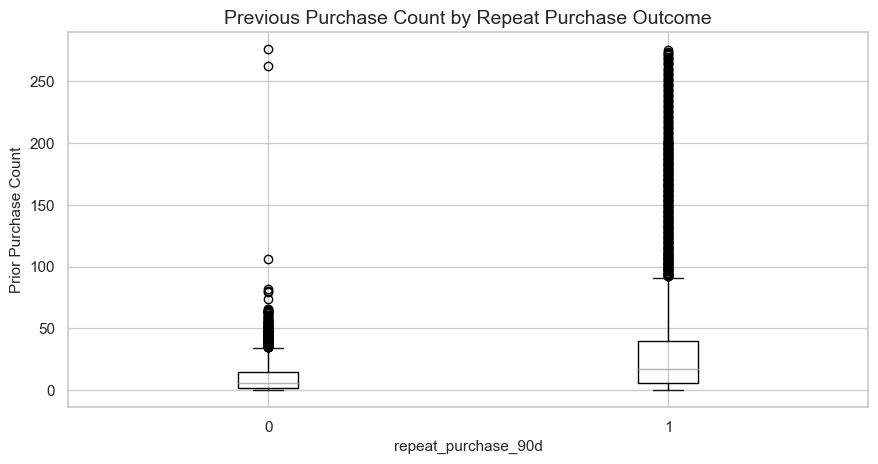

In [20]:
# Compare the distribution of previous purchase counts by target class.
train.boxplot(
    column="prior_purchase_count",
    by="repeat_purchase_90d"
)

plt.title("Previous Purchase Count by Repeat Purchase Outcome")
plt.suptitle("")
plt.xlabel("repeat_purchase_90d")
plt.ylabel("Prior Purchase Count");

### Interpretation

Previous purchase frequency differs substantially between the two target
classes. 

- Observations with "repeat_purchase_90d = 1" have a median of 17 and a mean of 33.62
- Observations with "repeat_purchase_90d = 0" have a median of 6 and a mean of 10.54

This indicates that, in this dataset, customers with a more extensive previous purchase history tend to be more frequently associated with a subsequent purchase within 90 days.

The distributions are strongly right-skewed, with a large number of high-value observations appearing beyond the upper whiskers, particularly for the repeat-purchase class. 

These observations are not treated as errors at this stage and will be considered later when evaluating preprocessing requirements.

There are also 65 missing values for "prior_purchase_count", which is consistent with the missing-value patterns identified earlier.

### 6.3 Target and Recency of Previous Purchase

To further investigate previous customer behaviour, we examine the relationship between "days_since_previous_purchase" and the target variable.

"days_since_previous_purchase" represents the number of days between the current purchase and the customer's previous purchase.

In [21]:
# Compare the time since the previous purchase across the two target classes.
recency_summary = (
    train.groupby("repeat_purchase_90d")["days_since_previous_purchase"]
    .agg(["count", "mean", "median", "min", "max"])
)

display(recency_summary)

,count,mean,median,min,max
repeat_purchase_90d,,,,,
0,2363,139.876,105.000,-4.000,"2,324.000"
1,3310,74.155,37.000,-4.000,"3,199.000"


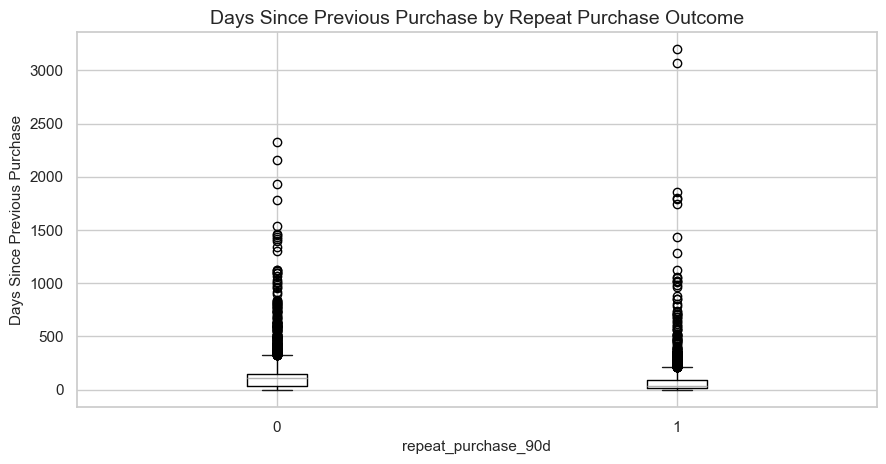

In [22]:
# Compare the distribution of days since the previous purchase by target class.
train.boxplot(
    column="days_since_previous_purchase",
    by="repeat_purchase_90d"
)

plt.title("Days Since Previous Purchase by Repeat Purchase Outcome")
plt.suptitle("")
plt.xlabel("repeat_purchase_90d")
plt.ylabel("Days Since Previous Purchase");

### Interpretation

The time since the previous purchase is quite different between the two target classes. Observations with repeat_purchase_90d = 1 have a median of 37 days since the previous purchase, compared with 105 days for repeat_purchase_90d = 0. The means show the same pattern, at 74.16 days for the repeat-purchase class and 139.88 days for the non-repeat class.

This suggests that, in this dataset, customers who purchased more recently are more often associated with a subsequent purchase within 90 days.

The distribution is strongly right-skewed, with many observations above the upper whisker. The maximum values are 2,324 days for the non-repeat class and 3,199 days for the repeat-purchase class.

The minimum value is -4 days for both classes. Since days_since_previous_purchase represents the number of days between the current and previous purchase, negative values are not consistent with the meaning of the variable. These values will therefore be flagged as a data-quality issue and investigated during preprocessing, rather than changed during EDA.

### 6.4 Target and Customer Tenure

To further investigate differences in customer history between the two target
classes, we examine the relationship between `customer_tenure_days` and the
target variable.

`customer_tenure_days` represents customer tenure in days at the purchase
date. The starting reference for this measure requires confirmation.

In [23]:
# Compare customer tenure across the two target classes.
tenure_summary = (
    train.groupby("repeat_purchase_90d")["customer_tenure_days"]
    .agg(["count", "mean", "median", "min", "max"])
)

display(tenure_summary)

,count,mean,median,min,max
repeat_purchase_90d,,,,,
0,2848,"1,000.698",781.000,0.000,"3,442.000"
1,3621,"1,198.441","1,032.000",0.000,"3,506.000"


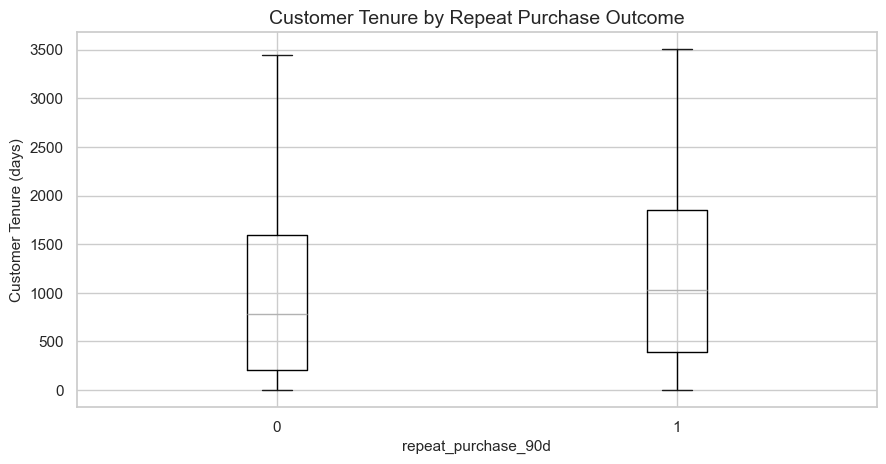

In [24]:
# Compare the distribution of customer tenure by target class.
train.boxplot(
    column="customer_tenure_days",
    by="repeat_purchase_90d"
)

plt.title("Customer Tenure by Repeat Purchase Outcome")
plt.suptitle("")
plt.xlabel("repeat_purchase_90d")
plt.ylabel("Customer Tenure (days)");

### Interpretation

Customer tenure also differs between the two target classes. Observations with repeat_purchase_90d = 1 have a median customer tenure of 1,032 days, compared with 781 days for repeat_purchase_90d = 0. The mean shows the same pattern, at 1,198.44 days for the repeat-purchase class and 1,000.70 days for the non-repeat class.

This suggests that, in this dataset, repeat-purchase observations tend to be associated with customers with longer recorded tenure. The difference is smaller than what we observed for previous purchase frequency and time since the previous purchase, but the pattern is consistent for both the mean and median.

Customer tenure ranges from 0 to around 3,500 days, and there are no obvious issues with the minimum values. However, the starting point used to calculate customer tenure still needs to be confirmed.

There are also 65 missing values for customer_tenure_days, which is consistent with the missing-value patterns identified earlier.

### 6.5 Target and Previous Spending Behaviour

To examine whether previous spending behaviour differs between the two target
classes, we analyse `prior_total_spend` and `prior_mean_purchase_value`.

`prior_total_spend` represents total spending across previous purchases,
while `prior_mean_purchase_value` represents the mean value of previous
purchases.

In [25]:
# Compare previous total spending across the two target classes.
spending_summary = (
    train.groupby("repeat_purchase_90d")["prior_total_spend"]
    .agg(["count", "mean", "median", "min", "max"])
)

display(spending_summary)

,count,mean,median,min,max
repeat_purchase_90d,,,,,
0,2848,"9,714.561","3,246.525",0.000,"230,354.060"
1,3621,"26,139.475","12,098.990",0.000,"247,865.100"


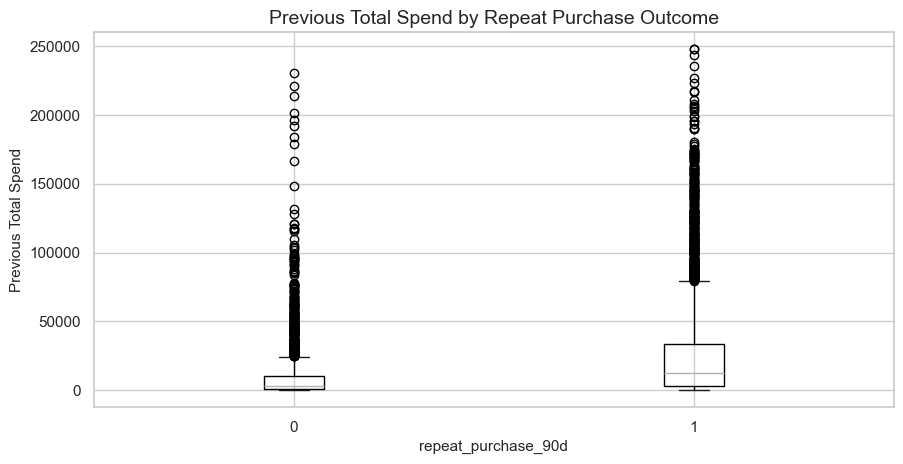

In [26]:
# Compare the distribution of previous total spending by target class.
train.boxplot(
    column="prior_total_spend",
    by="repeat_purchase_90d"
)

plt.title("Previous Total Spend by Repeat Purchase Outcome")
plt.suptitle("")
plt.xlabel("repeat_purchase_90d")
plt.ylabel("Previous Total Spend");

In [27]:
# Compare the mean previous purchase value across the two target classes.
mean_purchase_value_summary = (
    train.groupby("repeat_purchase_90d")["prior_mean_purchase_value"]
    .agg(["count", "mean", "median", "min", "max"])
)

display(mean_purchase_value_summary)

,count,mean,median,min,max
repeat_purchase_90d,,,,,
0,2365,"2,537,890.958",632.413,-883.510,"1,000,000,000.000"
1,3307,"3,024,880.886",789.940,"-2,478.658","1,000,000,000.000"


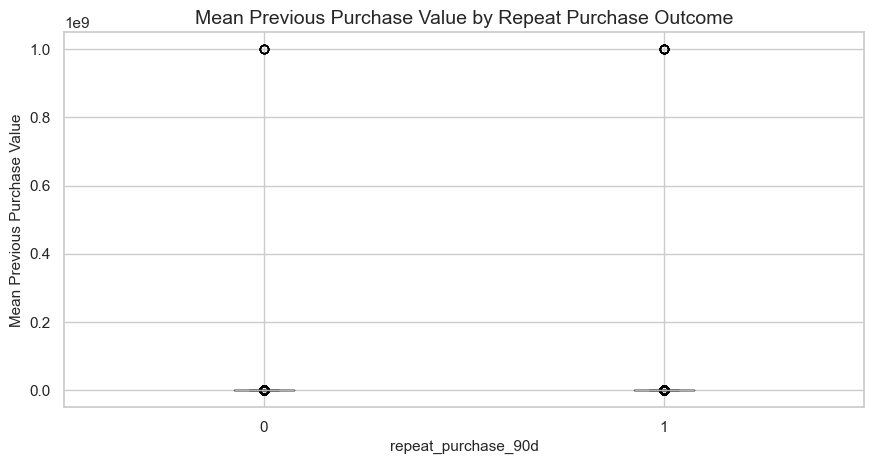

In [28]:
# Compare the distribution of previous mean purchase value by target class.
train.boxplot(
    column="prior_mean_purchase_value",
    by="repeat_purchase_90d"
)

plt.title("Mean Previous Purchase Value by Repeat Purchase Outcome")
plt.suptitle("")
plt.xlabel("repeat_purchase_90d")
plt.ylabel("Mean Previous Purchase Value");

### Interpretation

Previous spending also differs between the two target classes. For prior_total_spend, observations with repeat_purchase_90d = 1 have a much higher median previous spend (€12,098.99) than those with repeat_purchase_90d = 0 (€3,246.53). The means follow the same pattern, at €26,139.48 and €9,714.56, respectively.

This suggests that customers in the repeat-purchase class tend to have a higher total amount spent across their previous purchases.

The difference is smaller for prior_mean_purchase_value. The median is €789.94 for the repeat-purchase class and €632.41 for the non-repeat class, suggesting that the typical value of previous purchases is somewhat higher for customers in the repeat-purchase class.

However, this variable contains some extreme values. Both classes have a maximum value of 1,000,000,000, and negative values are also present. These extremes have a strong effect on the mean, making it less representative of a typical observation. For this reason, the median is more useful when comparing the two groups.

These unusual values will be investigated further during preprocessing, but no changes are made to them during EDA.

### note to add (somewhere)!!

We will still report the mean because it is useful for identifying the effect of extreme values, but we will rely more heavily on the median when describing the typical observation for strongly skewed variables.

### 6.6 Remaining Customer Purchase History Variables

The remaining historical variables describe the variability and range of
previous purchase values and the intervals between previous purchases.

Because several historical variables show strong skewness and extreme values,
both mean and median are reported. The median is particularly useful for
describing the typical observation because it is less affected by extreme
values, while differences between the mean and median can help identify
skewness or the influence of unusually large or small observations.

In [29]:
# Summarise the remaining customer purchase history variables by target class.
remaining_history_vars = [
    "prior_std_purchase_value",
    "prior_min_purchase_value",
    "prior_max_purchase_value",
    "prior_mean_gap_days",
    "prior_std_gap_days"
]

remaining_history_summary = (
    train.groupby("repeat_purchase_90d")[remaining_history_vars]
    .agg(["count", "mean", "median", "min", "max"])
)

display(remaining_history_summary)

variable            prior_std_purchase_value                                  \
                                       count    mean  median   min       max   
repeat_purchase_90d                                                            
0                                       2167 628.057 426.383 0.000 6,770.221   
1                                       3254 810.333 650.038 0.000 5,158.562   

variable            prior_min_purchase_value                                 \
                                       count    mean median   min       max   
repeat_purchase_90d                                                           
0                                       2446 233.242 88.110 0.930 6,298.980   
1                                       3420 151.289 45.510 0.930 5,575.280   

variable            prior_max_purchase_value                            \
                                       count      mean    median   min   
repeat_purchase_90d                                                      
0                                       2446 2,249.205 1,342.620 9.080   
1                                       3420 3,445.000 2,306.250 3.310   

variable                        prior_mean_gap_days                         \
                            max               count    mean  median    min   
repeat_purchase_90d                                                          
0                   121,251.532                2100 131.473 101.265 -4.000   
1                   267,526.190                3126  71.964  55.500 -4.000   

variable                      prior_std_gap_days                       \
                          max              count    mean median   min   
repeat_purchase_90d                                                     
0                   3,199.000               1948 100.434 65.064 1.414   
1                   2,524.000               3108  57.652 43.615 0.000   

variable                       
                          max  
repeat_purchase_90d            
0                   2,212.537  
1                   2,013.133

In [30]:
# Create a compact summary with one row per variable and target class.
compact_history_summary = []

for variable in remaining_history_vars:
    for target_value in [0, 1]:
        values = train.loc[
            train["repeat_purchase_90d"] == target_value,
            variable
        ]

        compact_history_summary.append({
            "variable": variable,
            "target": target_value,
            "count": values.count(),
            "mean": values.mean(),
            "median": values.median(),
            "min": values.min(),
            "max": values.max()
        })

compact_history_summary = pd.DataFrame(compact_history_summary)

display(compact_history_summary)

,variable,target,count,mean,median,min,max
0,prior_std_purchase_value,0,2167,628.057,426.383,0.000,"6,770.221"
1,prior_std_purchase_value,1,3254,810.333,650.038,0.000,"5,158.562"
2,prior_min_purchase_value,0,2446,233.242,88.110,0.930,"6,298.980"
3,prior_min_purchase_value,1,3420,151.289,45.510,0.930,"5,575.280"
4,prior_max_purchase_value,0,2446,"2,249.205","1,342.620",9.080,"121,251.532"
5,prior_max_purchase_value,1,3420,"3,445.000","2,306.250",3.310,"267,526.190"
6,prior_mean_gap_days,0,2100,131.473,101.265,-4.000,"3,199.000"
7,prior_mean_gap_days,1,3126,71.964,55.500,-4.000,"2,524.000"
8,prior_std_gap_days,0,1948,100.434,65.064,1.414,"2,212.537"
9,prior_std_gap_days,1,3108,57.652,43.615,0.000,"2,013.133"


### Interpretation

The remaining customer-history variables also show some differences between the two target classes.

For purchase-value variability, prior_std_purchase_value is higher for the repeat-purchase class, with a median of 650.04 compared with 426.38 for the non-repeat class. On the other hand, prior_min_purchase_value has a lower median for the repeat-purchase class (45.51 compared with 88.11). prior_max_purchase_value shows the opposite pattern, with a higher median for the repeat-purchase class (2,306.25 compared with 1,342.62).

The variables related to purchase intervals show a clearer difference between the two classes. prior_mean_gap_days has a median of 55.50 days for the repeat-purchase class, compared with 101.27 days for the non-repeat class. Similarly, prior_std_gap_days has a lower median for the repeat-purchase class (43.62 compared with 65.06). Overall, this suggests that customers in the repeat-purchase class tend to make previous purchases closer together and with less variation in the time between purchases.

For several of these variables, the mean is noticeably higher than the median, which suggests that the distributions are skewed. For this reason, the median is more useful for describing a typical observation, while the mean still helps show the effect of extreme values.

The minimum value of prior_mean_gap_days is -4 days in both target classes. Since this variable represents the mean number of days between previous purchases, negative values do not match its documented meaning. These values will be investigated during preprocessing, but no changes are made during EDA.

### 6.7 Target and Recent Purchase Activity

We next examine customer purchase activity in the historical time windows
preceding the current purchase.

The 30-day window is analysed first using `purchase_count_30d` and
`spend_30d`. These variables represent the number of purchases and total
spending in the 30-day window, respectively.

The exact construction of these windows requires confirmation, particularly
whether the current purchase is excluded and how the window boundaries are
defined.

In [31]:
# Compare purchase frequency in the previous 30-day window across target classes.
purchase_count_30d_summary = (
    train.groupby("repeat_purchase_90d")["purchase_count_30d"]
    .agg(["count", "mean", "median", "min", "max"])
)

display(purchase_count_30d_summary)

,count,mean,median,min,max
repeat_purchase_90d,,,,,
0,2848,0.240,0.000,0.000,5.000
1,3621,0.884,0.000,0.000,11.000


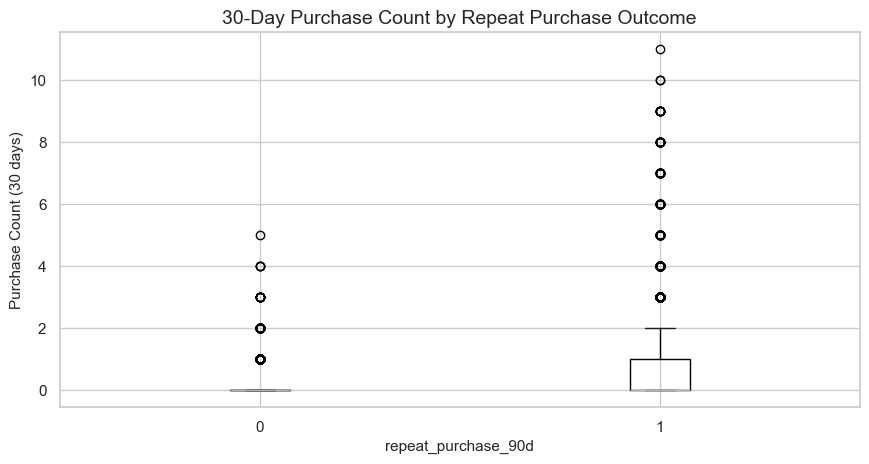

In [32]:
# Compare the distribution of 30-day purchase counts by target class.
train.boxplot(
    column="purchase_count_30d",
    by="repeat_purchase_90d"
)

plt.title("30-Day Purchase Count by Repeat Purchase Outcome")
plt.suptitle("")
plt.xlabel("repeat_purchase_90d")
plt.ylabel("Purchase Count (30 days)");

In [33]:
# Compare spending in the previous 30-day window across target classes.
spend_30d_summary = (
    train.groupby("repeat_purchase_90d")["spend_30d"]
    .agg(["count", "mean", "median", "min", "max"])
)

display(spend_30d_summary)

,count,mean,median,min,max
repeat_purchase_90d,,,,,
0,2848,235.287,0.000,0.000,"11,457.010"
1,3621,631.634,0.000,0.000,"22,297.210"


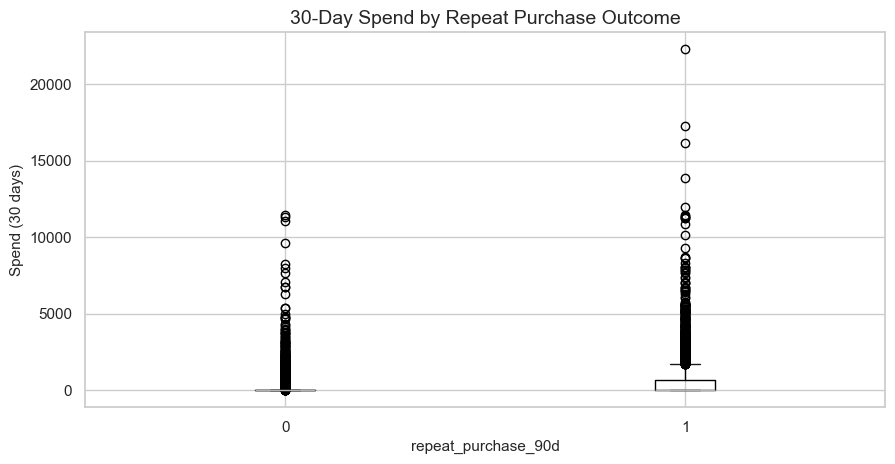

In [34]:
# Compare the distribution of 30-day spending by target class.
train.boxplot(
    column="spend_30d",
    by="repeat_purchase_90d"
)

plt.title("30-Day Spend by Repeat Purchase Outcome")
plt.suptitle("")
plt.xlabel("repeat_purchase_90d")
plt.ylabel("Spend (30 days)");

In [35]:
# Calculate the percentage of observations with at least one
# purchase and with positive spending in the previous 30 days.

activity_30d_summary = pd.DataFrame({
    "purchase_count_30d > 0 (%)": (
        train.groupby("repeat_purchase_90d")["purchase_count_30d"]
        .apply(lambda x: (x > 0).mean() * 100)
    ),
    "spend_30d > 0 (%)": (
        train.groupby("repeat_purchase_90d")["spend_30d"]
        .apply(lambda x: (x > 0).mean() * 100)
    )
})

display(activity_30d_summary)

,purchase_count_30d > 0 (%),spend_30d > 0 (%)
repeat_purchase_90d,,
0,20.243,20.243
1,42.255,42.255


### Interpretation

Recent 30-day purchase activity differs quite clearly between the two target classes. Only 20.24% of observations with repeat_purchase_90d = 0 have at least one purchase in the previous 30 days, compared with 42.26% of observations with repeat_purchase_90d = 1.

The same pattern can be seen in spend_30d, since the proportion of observations with positive spending is the same in both target classes. This means that, in this dataset, having at least one purchase in the previous 30 days is closely aligned with having positive spending during the same period.

The median of both variables is 0 for both target classes because most observations have no activity in this 30-day window. Because of this, looking at the proportion of observations with any activity gives a clearer picture of the difference between the two groups.

Overall, observations with repeat_purchase_90d = 1 show more recent purchase activity in the previous 30 days. This is a descriptive relationship and does not mean that recent activity causes a repeat purchase.

### 6.8 Target and 90-Day Historical Activity

We next examine purchase frequency and spending in the historical 90-day
window using `purchase_count_90d` and `spend_90d`.

These variables are particularly relevant to the target analysis because the
target measures whether another purchase occurs within the following 90 days.
The historical 90-day variables refer to a preceding time window, but the
exact construction of this window, including whether the current purchase is
excluded, requires confirmation.

The analysis therefore focuses first on describing the observed relationship
with the target without making assumptions about their suitability for
modelling.

In [36]:
# Compare purchase frequency in the historical 90-day window
# across the two target classes.
purchase_count_90d_summary = (
    train.groupby("repeat_purchase_90d")["purchase_count_90d"]
    .agg(["count", "mean", "median", "min", "max"])
)

display(purchase_count_90d_summary)

,count,mean,median,min,max
repeat_purchase_90d,,,,,
0,2848,0.531,0.000,0.000,9.000
1,3621,2.498,1.000,0.000,22.000


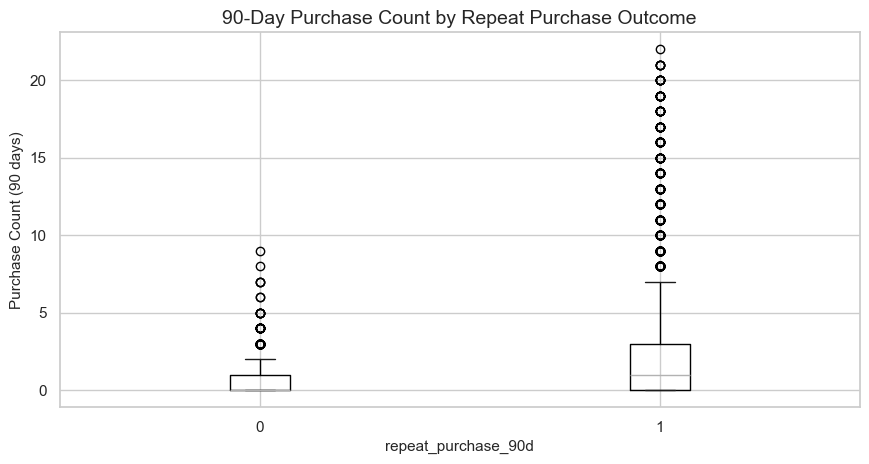

In [37]:
# Compare the distribution of 90-day purchase counts by target class.
train.boxplot(
    column="purchase_count_90d",
    by="repeat_purchase_90d"
)

plt.title("90-Day Purchase Count by Repeat Purchase Outcome")
plt.suptitle("")
plt.xlabel("repeat_purchase_90d")
plt.ylabel("Purchase Count (90 days)");

In [38]:
# Calculate the percentage of observations with at least one purchase
# in the historical 90-day window.

activity_90d_summary = pd.DataFrame({
    "purchase_count_90d > 0 (%)": (
        train.groupby("repeat_purchase_90d")["purchase_count_90d"]
        .apply(lambda x: (x > 0).mean() * 100)
    )
})

display(activity_90d_summary)

,purchase_count_90d > 0 (%)
repeat_purchase_90d,
0,36.597
1,69.130


### Interpretation

Historical 90-day purchase activity differs substantially between the two
target classes. The mean number of purchases is 0.531 for
`repeat_purchase_90d = 0` and 2.498 for `repeat_purchase_90d = 1`, while the
median is 0 and 1, respectively.

The proportion of observations with at least one purchase in the historical
90-day window provides an even clearer comparison. Only 36.60% of observations
in the non-repeat class have at least one previous purchase, compared with
69.13% in the repeat-purchase class.

Compared with the 30-day window, the same pattern is observed at a broader
time horizon: recent historical purchase activity is more common among
observations associated with a repeat purchase.

These results are descriptive associations only. Before these variables are
considered for modelling, the exact construction of the historical window and
whether the current purchase is excluded should be confirmed.

In [40]:
# Compare spending in the historical 90-day window across target classes.
spend_90d_summary = (
    train.groupby("repeat_purchase_90d")["spend_90d"]
    .agg(["count", "mean", "median", "min", "max"])
)

display(spend_90d_summary)

,count,mean,median,min,max
repeat_purchase_90d,,,,,
0,2848,541.734,0.000,0.000,"18,640.590"
1,3621,"1,813.371",746.190,0.000,"30,234.880"


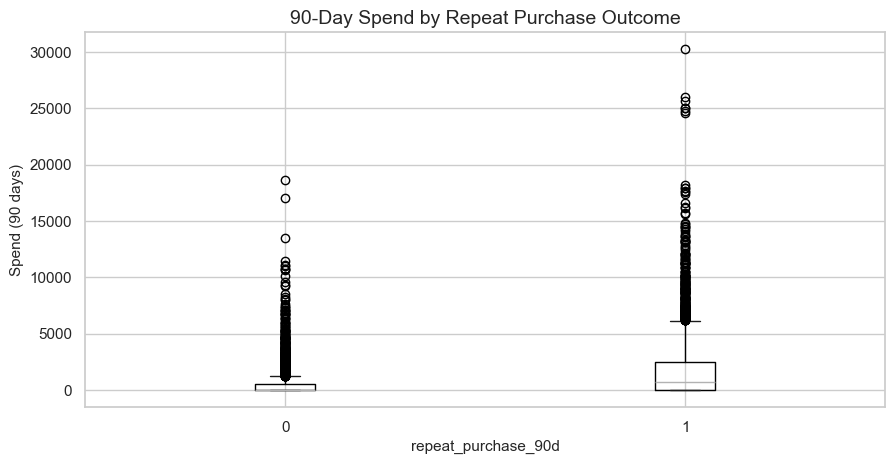

In [41]:
# Compare the distribution of historical 90-day spending by target class.
train.boxplot(
    column="spend_90d",
    by="repeat_purchase_90d"
)

plt.title("90-Day Spend by Repeat Purchase Outcome")
plt.suptitle("")
plt.xlabel("repeat_purchase_90d")
plt.ylabel("Spend (90 days)");

In [42]:
# Calculate the percentage of observations with positive spending
# in the historical 90-day window.

spend_90d_activity = (
    train.groupby("repeat_purchase_90d")["spend_90d"]
    .apply(lambda x: (x > 0).mean() * 100)
    .to_frame("spend_90d > 0 (%)")
)

display(spend_90d_activity)

,spend_90d > 0 (%)
repeat_purchase_90d,
0,36.597
1,69.130


### Interpretation

Historical 90-day spending also shows a clear difference between the two target classes. Observations with repeat_purchase_90d = 1 have a median spend_90d of €746.19, compared with 0 for repeat_purchase_90d = 0. The mean follows the same pattern, at €1,813.37 for the repeat-purchase class and €541.73 for the non-repeat class.

Looking at the proportion of observations with positive spending gives a similar picture. Positive spend_90d is observed in 69.13% of the repeat-purchase class, compared with 36.60% of the non-repeat class. These percentages are the same as those obtained for purchase_count_90d > 0, meaning that positive purchase activity and positive spending are aligned in this dataset.

Overall, observations with repeat_purchase_90d = 1 tend to show both more frequent and higher purchase activity during the previous 90 days.

As with purchase_count_90d, these results describe an association between the variables and the target. The exact construction of the 90-day historical window should still be confirmed before deciding how these variables should be used in the modelling stage.

### 6.9 Longer-Term Historical Activity

To complement the 30-day and 90-day analyses, we examine purchase activity
over the longer 180-day and 365-day historical windows.

Rather than repeating separate visualisations for each variable, the longer
windows are summarised using the mean, median, and proportion of observations
with positive activity. This provides a compact comparison of customer
activity across different historical horizons.

In [43]:
# Compare purchase frequency and spending across the 180-day and 365-day
# historical windows by target class.

long_term_activity_summary = pd.DataFrame({
    "purchase_count_180d_mean": (
        train.groupby("repeat_purchase_90d")["purchase_count_180d"].mean()
    ),
    "purchase_count_180d_median": (
        train.groupby("repeat_purchase_90d")["purchase_count_180d"].median()
    ),
    "purchase_count_180d > 0 (%)": (
        train.groupby("repeat_purchase_90d")["purchase_count_180d"]
        .apply(lambda x: (x > 0).mean() * 100)
    ),
    "spend_180d_mean": (
        train.groupby("repeat_purchase_90d")["spend_180d"].mean()
    ),
    "spend_180d_median": (
        train.groupby("repeat_purchase_90d")["spend_180d"].median()
    ),
    "spend_180d > 0 (%)": (
        train.groupby("repeat_purchase_90d")["spend_180d"]
        .apply(lambda x: (x > 0).mean() * 100)
    ),
    "purchase_count_365d_mean": (
        train.groupby("repeat_purchase_90d")["purchase_count_365d"].mean()
    ),
    "purchase_count_365d_median": (
        train.groupby("repeat_purchase_90d")["purchase_count_365d"].median()
    ),
    "purchase_count_365d > 0 (%)": (
        train.groupby("repeat_purchase_90d")["purchase_count_365d"]
        .apply(lambda x: (x > 0).mean() * 100)
    ),
    "spend_365d_mean": (
        train.groupby("repeat_purchase_90d")["spend_365d"].mean()
    ),
    "spend_365d_median": (
        train.groupby("repeat_purchase_90d")["spend_365d"].median()
    ),
    "spend_365d > 0 (%)": (
        train.groupby("repeat_purchase_90d")["spend_365d"]
        .apply(lambda x: (x > 0).mean() * 100)
    )
})

display(long_term_activity_summary.round(2))

,purchase_count_180d_mean,purchase_count_180d_median,purchase_count_180d > 0 (%),spend_180d_mean,spend_180d_median,spend_180d > 0 (%),purchase_count_365d_mean,purchase_count_365d_median,purchase_count_365d > 0 (%),spend_365d_mean,spend_365d_median,spend_365d > 0 (%)
repeat_purchase_90d,,,,,,,,,,,,
0,1.320,1.000,66.490,"1,286.170",457.870,66.490,2.600,2.000,78.990,"1,812,450.990","1,138.940",76.560
1,4.990,3.000,86.040,"3,723.750","2,106.220",86.040,9.680,5.000,91.710,"2,856,182.770","4,552.940",88.780


### Interpretation

The longer historical windows reinforce the pattern seen in the 30-day and 90-day measures. Observations with repeat_purchase_90d = 1 consistently show higher purchase frequency and spending than observations with repeat_purchase_90d = 0.

For the 180-day window, the repeat-purchase class has a median of 3 previous purchases, compared with 1 for the non-repeat class. Positive purchase activity is also more common in the repeat-purchase class, at 86.04% compared with 66.49%.

The same pattern can be seen over 365 days. The median number of previous purchases is 5 for the repeat-purchase class and 2 for the non-repeat class, while positive purchase activity occurs in 91.71% and 78.99% of observations, respectively.

The spending variables are strongly right-skewed, especially spend_365d. For this variable, the mean is much higher than the median, which is consistent with the extreme values identified earlier in the EDA. This means that the mean is strongly affected by unusually large observations, so the median gives a better picture of typical spending.

Overall, the results show a consistent descriptive relationship between historical customer activity and the repeat-purchase outcome. The extreme values in the spending variables will be investigated during preprocessing, but no values are modified or removed during EDA.

### Summary of Target-Related Findings

The table below summarises the main descriptive differences observed between
the two target classes. Median values are emphasised for variables with
strongly skewed distributions, as they are less sensitive to extreme
observations than the mean.

In [45]:
target_findings = pd.DataFrame({
    "Measure": [
    "Target observations",
    "Previous purchase count",
    "Customer tenure (days)",
    "Previous total spend",
    "Positive purchase activity - 30d",
    "Positive purchase activity - 90d",
    "Positive purchase activity - 180d",
    "Positive purchase activity - 365d"
],
    
    "repeat_purchase_90d = 0": [
        "2,848 (44.08%)",
        "Median = 6",
        "Median = 781 days",
        "Median = €3,246.53",
        "20.24% with activity",
        "36.60% with activity",
        "66.49% with activity",
        "78.99% with activity"
    ],
    
    "repeat_purchase_90d = 1": [
        "3,621 (55.92%)",
        "Median = 17",
        "Median = 1,032 days",
        "Median = €12,098.99",
        "42.26% with activity",
        "69.13% with activity",
        "86.04% with activity",
        "91.71% with activity"
    ]
})

display(target_findings)

,Measure,repeat_purchase_90d = 0,repeat_purchase_90d = 1
0,Target observations,"2,848 (44.08%)","3,621 (55.92%)"
1,Previous purchase count,Median = 6,Median = 17
2,Customer tenure (days),Median = 781 days,"Median = 1,032 days"
3,Previous total spend,"Median = €3,246.53","Median = €12,098.99"
4,Positive purchase activity - 30d,20.24% with activity,42.26% with activity
5,Positive purchase activity - 90d,36.60% with activity,69.13% with activity
6,Positive purchase activity - 180d,66.49% with activity,86.04% with activity
7,Positive purchase activity - 365d,78.99% with activity,91.71% with activity


### Overall Interpretation

The target analysis shows consistent differences between the two classes. Observations with repeat_purchase_90d = 1 generally have a more active historical purchase profile, including more previous purchases, longer customer tenure, higher historical spending, and more purchase activity across the 30-day, 90-day, 180-day, and 365-day windows.

The difference is particularly clear when looking at recent and historical purchase activity. For example, 69.13% of observations in the repeat-purchase class have positive purchase activity in the previous 90 days, compared with 36.60% in the non-repeat class.

The target is also relatively balanced, with 44.08% of observations belonging to class 0 and 55.92% to class 1.

Overall, these results suggest that historical customer activity is worth considering in the following modelling stages. However, the relationships observed here are descriptive and do not by themselves show causality or predictive importance.

The extreme values found in several spending variables will be investigated during preprocessing rather than modified during EDA.